<a href="https://colab.research.google.com/github/olafisoyetope44-ship-it/Video-Game-Analysis/blob/main/Video_Games_Sales_Visualization_and_Prediction_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Data Import

In [27]:
# Importing the required libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import missingno as mn
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import norm, skew
import seaborn as sns

# Visualization Packages Importing
from plotly import express as px
from plotly import graph_objects as go
from plotly.subplots import make_subplots



In [28]:
from google.colab import files
import io

print("Please select and upload 'vgsales.csv' (or 'Video_Games_Sales.csv') from your computer:")
uploaded = files.upload()

# Get the first uploaded filename
for filename in uploaded.keys():
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print(f"\nSuccessfully uploaded and loaded {len(df):,} rows from '{filename}'!")
    display(df.head())


Please select and upload 'vgsales.csv' (or 'Video_Games_Sales.csv') from your computer:


Saving vgsales.csv to vgsales (5).csv

Successfully uploaded and loaded 16,598 rows from 'vgsales (5).csv'!


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [29]:
df.shape

(16598, 11)

In [30]:
# To view the columns with missing values
df.isnull().sum()


,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


In [31]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [32]:
df.dropna(inplace=True)

In [33]:
df['Year'] = df['Year'].astype(int)

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  object 
 2   Platform      16291 non-null  object 
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  object 
 5   Publisher     16291 non-null  object 
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB


##Data Visualization

In [35]:
df1 = df.copy()

1.What are the Sales & Share of games in different genre?

In [36]:
genre_sales = (
    df1.groupby("Genre")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
)

fig = px.pie(
    values=genre_sales.values,
    names=genre_sales.index,
    hole=0.5,
    title="Share of Recorded Global Video-Game Sales by Genre"
)

fig.update_traces(
    textposition="inside",
    textinfo="label+percent"
)

fig.update_layout(title_x=0.5, height=700)
fig.show()

### Key Finding

The chart compares the share of recorded global video game sales contributed by each genre. Action and Sports are among the important genres in the dataset, but their relative contributions should be assessed using total sales rather than the number of games released.

This distinction matters because a genre can have many game releases without necessarily generating the highest sales. Measuring each genre's share of global sales provides a more useful view of its commercial contribution.

In [37]:
df1['Year'].unique()

array([2006, 1985, 2008, 2009, 1996, 1989, 1984, 2005, 1999, 2007, 2010,
       2013, 2004, 1990, 1988, 2002, 2001, 2011, 1998, 2015, 2012, 2014,
       1992, 1997, 1993, 1994, 1982, 2003, 1986, 2000, 1995, 2016, 1991,
       1981, 1987, 1980, 1983, 2020, 2017])

**2.In Which Year the Video Games realsed most and what % they hold in market?**

/tmp/ipykernel_37601/670373638.py:3: FutureWarning:

pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.



Text(0.5, 1.0, 'Number of video game releases each period')

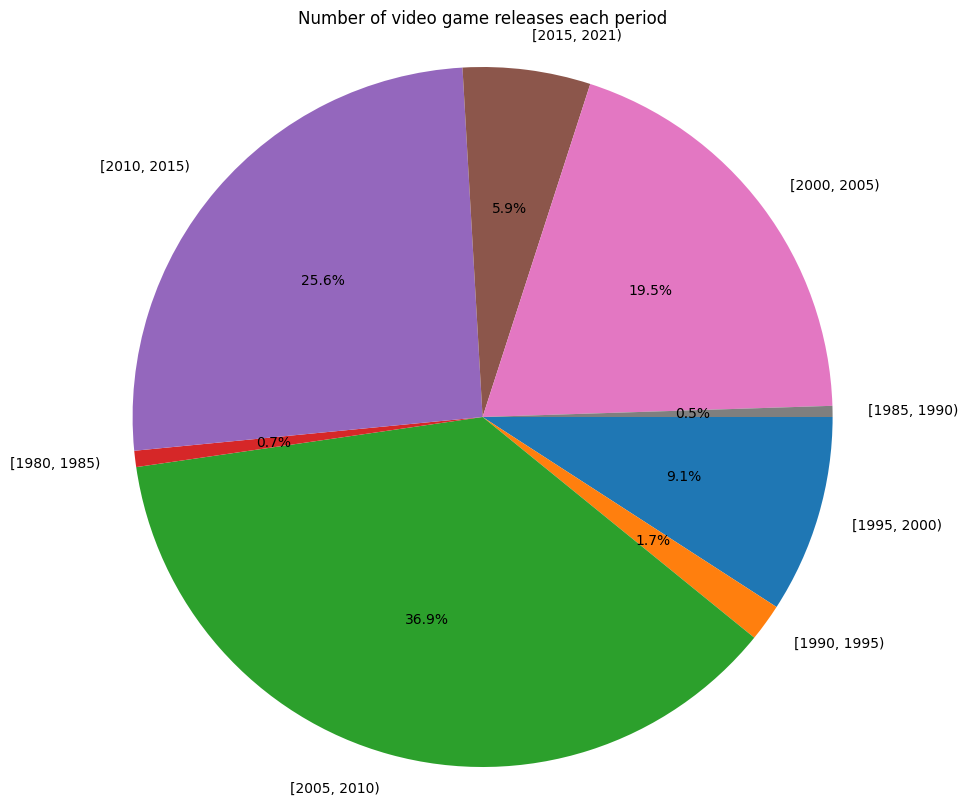

In [38]:
bins = [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2021]
cats = pd.cut(df1['Year'], bins, right = False)
year = pd.DataFrame(pd.value_counts(cats))
years = year.sample(frac = 1)
fig = plt.figure(figsize=(20,10)), plt.pie(np.array(years).ravel(), labels = years.index, autopct = '%1.1f%%', counterclock = False);
plt.axis('square')
plt.title('Number of video game releases each period')

### Key Finding

The distribution of video game releases across time periods helps identify when the industry experienced the greatest volume of recorded releases. Comparing these periods provides context for the growth and subsequent changes in the video game market.

The chart measures the **number of games released**, not sales revenue. Therefore, a period with more releases does not necessarily represent the period with the highest sales. The results should also be interpreted with the dataset's coverage and missing release-year values in mind.

**3.What are the Sales of diffrent genres of Games in NA,EU,JP, Global and Other Markets?**

In [39]:
col = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Global_Sales', 'Other_Sales']
title = ['North America', 'Europe', 'Japan', 'Global', 'Other']

for i, c in enumerate(col):
    genre = (
        df1.groupby('Genre', as_index=False)[c]
        .sum()
        .sort_values(c, ascending=False)
    )

    fig = px.bar(
        genre,
        x='Genre',
        y=c,
        title=f'Sales of Different Game Genres in the {title[i]} Market',
        labels={
            'Genre': 'Game Genre',
            c: f'{title[i]} Sales (millions)'
        },
        color='Genre'
    )

    fig.show()

### Key Finding

The regional sales comparison highlights differences in genre performance across markets. Action games contribute strongly to sales in North America, Europe, and other markets, while Role-Playing games have a particularly strong presence in Japan.

These differences demonstrate why regional analysis is valuable: a genre's commercial performance in one market may not reflect its performance elsewhere. For businesses, publishers, and developers, understanding these variations can support more informed decisions about regional marketing and product positioning.

**Analytical note:** These charts compare total recorded sales by genre, not sales per individual game. A genre with higher total sales may have more releases as well as stronger individual titles.


**4.How much of the Number of Popular games available in Platform?**

/tmp/ipykernel_37601/3219477859.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




Text(0.5, 1.0, 'Number of popular games by platform')

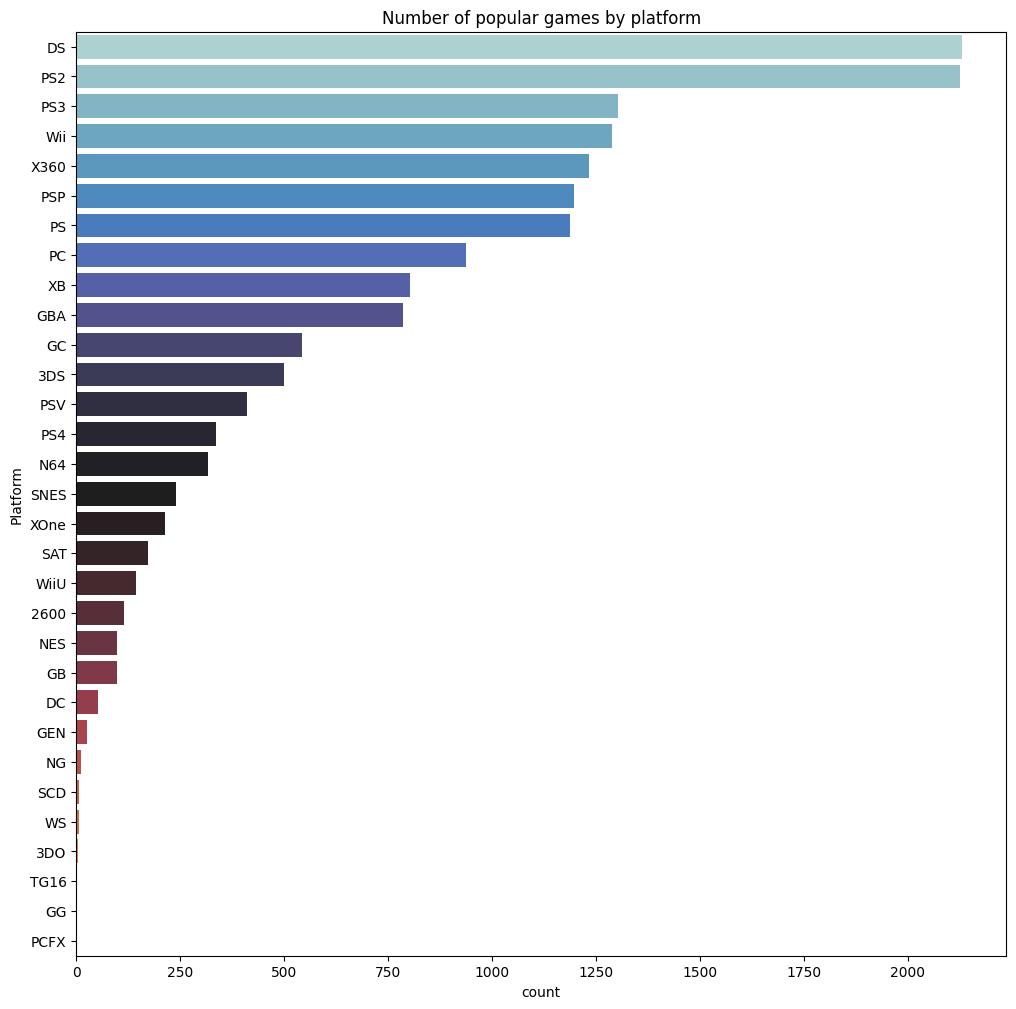

In [40]:
fig = plt.figure(figsize = (12,12))
sns.countplot(y='Platform',order = df1['Platform'].value_counts().index[0:31],data = df1,palette='icefire')
plt.title('Number of popular games by platform')

### Key Finding

The platform comparison shows how video game releases are distributed across different gaming systems. Platforms with more recorded game releases have a larger representation in this dataset, which can help illustrate the development of the gaming market over time.

However, the number of games released on a platform does not necessarily indicate higher sales, greater player demand, or stronger profitability. These questions would require additional analysis of sales by platform and, where available, player engagement and commercial performance.

**Business implication:** Platform release counts provide useful context, but they should be combined with sales data before drawing conclusions about market success.

**5.What are the Top 10 Video Games Publishers in Diffrent Regions?**

In [41]:
# col = ['NA_Sales','EU_Sales', 'JP_Sales', 'Other_Sales']
# title = ['North America','Europe', 'Japan', 'Rest of the World']
col = ['NA_Sales','EU_Sales', 'JP_Sales','Global_Sales','Other_Sales']
title = ['North America','Europe', 'Japan','Global','Rest of the World']

for i,c in enumerate(col):
    top_10_publisher = df1.groupby('Publisher').sum().sort_values(c, ascending = False).head(10).reset_index()[['Publisher',c]]
    fig = px.bar(top_10_publisher, x='Publisher',y=c,title='Top 10 Video Game Publishers in {}'.format(title[i]),
       labels={'Name':'Game',c:title[i]}, color="Publisher")
    fig.show()

### Key Finding

The regional publisher comparisons show how recorded video game sales are distributed among major publishers in North America, Europe, Japan, and other markets. Comparing total sales by publisher helps identify companies with a strong presence in each region.

Publisher performance varies geographically, reflecting differences in game portfolios and regional market preferences. A publisher that performs strongly in one market may have a different position in another.

**Business implication:** Publishers can use regional sales comparisons to identify their strongest markets and investigate opportunities for growth in regions where their sales are comparatively lower.

**Analytical note:** These charts rank publishers by total recorded sales, not by profit, number of games released, or average sales per game.


**6.What are the Sales of Video games from year 1980-2020?**

In [42]:
fig=px.line(
    df.groupby(df.Year).sum().reset_index(),
    x='Year',
    y=['Global_Sales','NA_Sales','EU_Sales','JP_Sales','Other_Sales'],
    title='Sum of Sales by Year',
    )
fig.show()

### Key Finding

The annual sales trend illustrates how recorded video game sales changed over the period covered by the dataset. Comparing global sales with North American, European, Japanese, and other-market sales helps reveal differences in regional contributions and changes over time.

Annual sales totals can be affected by major releases, platform transitions, market conditions, and the coverage of the dataset. The latest years may also contain fewer recorded titles, so a decline in the chart should not automatically be interpreted as a decline in the overall video game industry.

**Business implication:** Historical sales trends can help identify important periods for further investigation, but additional market data is needed before making forecasts or investment decisions.


**7.What are the Average Sales of Video games from year 1980-2020?**

In [43]:
fig=px.line(
    df.groupby(df.Year).mean(numeric_only=True).reset_index(),
    x='Year',
    y=['Global_Sales','NA_Sales','EU_Sales','JP_Sales','Other_Sales'],
    title='Average of Sales by Year',
    )
fig.show()

### Key Finding

This chart compares average recorded video game sales per game by release year across global and regional markets. Unlike the previous chart, which shows total sales for each year, this chart shows the average sales value across the recorded games released in each year.

A high average may reflect a small number of successful titles or fewer recorded games in that year, while a high total may result from many releases. The results should therefore be interpreted alongside the annual release counts and total-sales chart.

**Analytical note:** Recent years may be incomplete in the dataset, so comparisons at the end of the period should be treated cautiously.

**8.What are the Top 10 Best Selling Video Games around the World?**

In [44]:
# col = ['NA_Sales','EU_Sales', 'JP_Sales', 'Other_Sales']
# title = ['North America','Europe', 'Japan', 'Rest of the World']
col = ['NA_Sales','EU_Sales', 'JP_Sales','Global_Sales','Other_Sales']
title = ['North America','Europe', 'Japan','Global','Rest of the World']


for i,c in enumerate(col):
    sale_df = df1.groupby('Name').sum().sort_values(c,ascending=False).head(10).reset_index()[['Name',c]]
    fig = px.bar(sale_df,x='Name',y=c,title='The 10 best selling games in {}'.format(title[i]),
                labels={'Name':'Games Name',c:title[i]+' Sales'},color='Name')
    fig.show()

### Key Finding

The top 10 best-selling video games highlight the titles with the highest recorded global sales in the dataset. Examining these games helps identify successful titles and provides insight into the games that achieved broad commercial reach.

These results reflect historical recorded sales and should not be treated as a ranking of today's most popular games. Sales figures may also be influenced by the platforms available, the period of release, and the markets in which each game was sold.

**Business implication:** Publishers and developers can use historical best-seller analysis to investigate successful genres, franchises, and platforms. However, sales alone do not explain why a game succeeded; further analysis would be needed to assess factors such as release timing, marketing, and player engagement.

In [45]:

sales_columns = {
    "NA_Sales": "North America",
    "EU_Sales": "Europe",
    "JP_Sales": "Japan",
    "Other_Sales": "Other Markets"
}

for column, market in sales_columns.items():
    # Select the top 10 game records independently for each market
    top_games = (
        df1.sort_values(column, ascending=False)
        .head(10)
        .copy()
    )

    fig = px.sunburst(
        top_games,
        path=["Genre", "Publisher", "Platform"],
        values=column,
        title=f"Top 10 Game Records by Sales — {market}"
    )

    fig.update_layout(
        margin=dict(t=50, l=10, r=10, b=10)
    )

    fig.show()


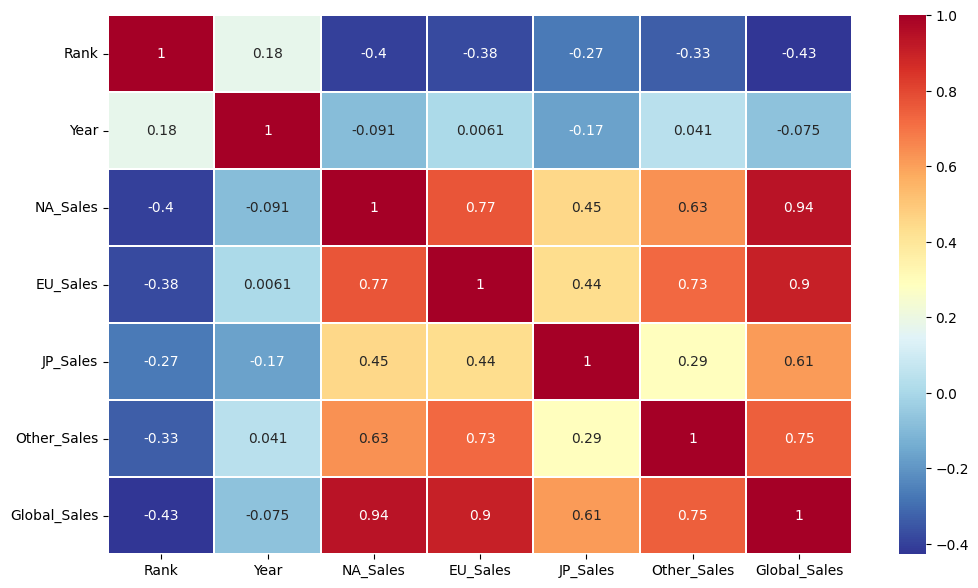

In [46]:
corr_ = df1.corr(numeric_only=True)

plt.figure(figsize=(12, 7))

sns.heatmap(corr_, annot=True, linewidths=.2, cmap='RdYlBu_r')

plt.show()

# Predictive Modelling — Leakage-Safe Evaluation

The earlier version used North American and European sales to predict global sales. Those regional values are components of global sales, so that setup leaks information from the target into the inputs and does not represent a genuine pre-release forecast.

This revised experiment uses only release metadata available before sales are observed: **platform, genre, publisher, and release year**. Categorical fields are one-hot encoded, missing values are imputed inside a pipeline, and preprocessing is refitted within each cross-validation fold.

The models are evaluated against a simple median baseline. Because sales are highly skewed, interpret MAE and RMSE alongside R²; a negative R² means the model performs worse than predicting the test-set mean. These results are a more defensible baseline, not proof that sales can be forecast accurately.

In [47]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use only information that could be known around release time.
categorical_features = ["Platform", "Genre", "Publisher"]
numeric_features = ["Year"]
feature_columns = categorical_features + numeric_features
target_column = "Global_Sales"

df_model = df[feature_columns + [target_column]].copy()
df_model = df_model.dropna(subset=[target_column])
X = df_model[feature_columns]
y = df_model[target_column].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Rows used for modelling: {len(df_model):,}")
print(f"Training rows: {len(X_train):,} | Holdout rows: {len(X_test):,}")
print(f"Features: {feature_columns}")
print("Regional sales columns are deliberately excluded to avoid target leakage.")

Rows used for modelling: 16,291
Training rows: 13,032 | Holdout rows: 3,259
Features: ['Platform', 'Genre', 'Publisher', 'Year']
Regional sales columns are deliberately excluded to avoid target leakage.


In [48]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_transformer, categorical_features),
    ("numeric", numeric_transformer, numeric_features)
])

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Ridge regression": Ridge(alpha=10.0),
    "Random forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=1
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error"
}

results = []
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    cv_scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        return_train_score=False
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "CV R² (mean)": cv_scores["test_r2"].mean(),
        "CV MAE (mean)": -cv_scores["test_mae"].mean(),
        "CV RMSE (mean)": np.sqrt(-cv_scores["test_mse"].mean()),
        "Holdout R²": r2_score(y_test, predictions),
        "Holdout MAE": mean_absolute_error(y_test, predictions),
        "Holdout RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })
    fitted_models[model_name] = pipeline

model_results = pd.DataFrame(results).sort_values("Holdout RMSE")
model_results.round(3)

,Model,CV R² (mean),CV MAE (mean),CV RMSE (mean),Holdout R²,Holdout MAE,Holdout RMSE
2,Random forest,0.099,0.482,1.330,0.109,0.501,1.952
1,Ridge regression,0.144,0.517,1.307,0.088,0.554,1.975
0,Median baseline,-0.071,0.464,1.461,-0.037,0.496,2.106


## Compare model performance

Use the **holdout metrics** for the final comparison. Cross-validation scores are calculated only on the training partition, and each fold learns its own preprocessing steps. The holdout set is not used to select model hyperparameters in this baseline comparison.

,Model,CV R² (mean),CV MAE (mean),CV RMSE (mean),Holdout R²,Holdout MAE,Holdout RMSE
2,Random forest,0.099,0.482,1.330,0.109,0.501,1.952
1,Ridge regression,0.144,0.517,1.307,0.088,0.554,1.975
0,Median baseline,-0.071,0.464,1.461,-0.037,0.496,2.106


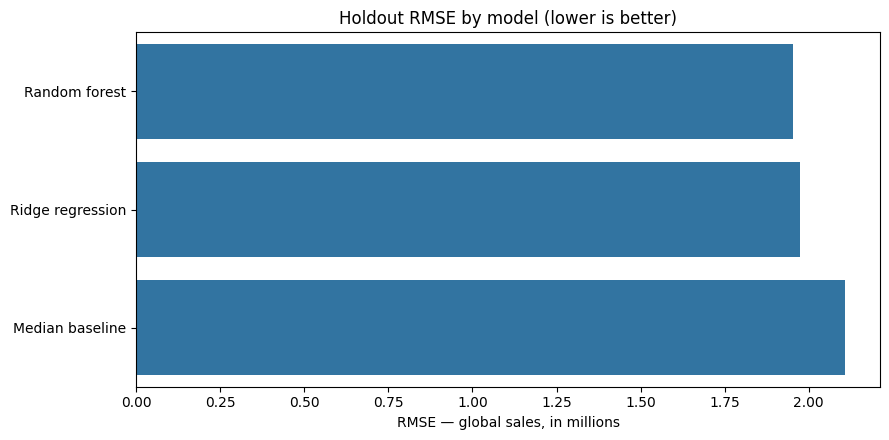

In [49]:
display(model_results.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_results = model_results.sort_values("Holdout RMSE", ascending=True)
sns.barplot(data=plot_results, x="Holdout RMSE", y="Model", ax=ax)
ax.set_title("Holdout RMSE by model (lower is better)")
ax.set_xlabel("RMSE — global sales, in millions")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

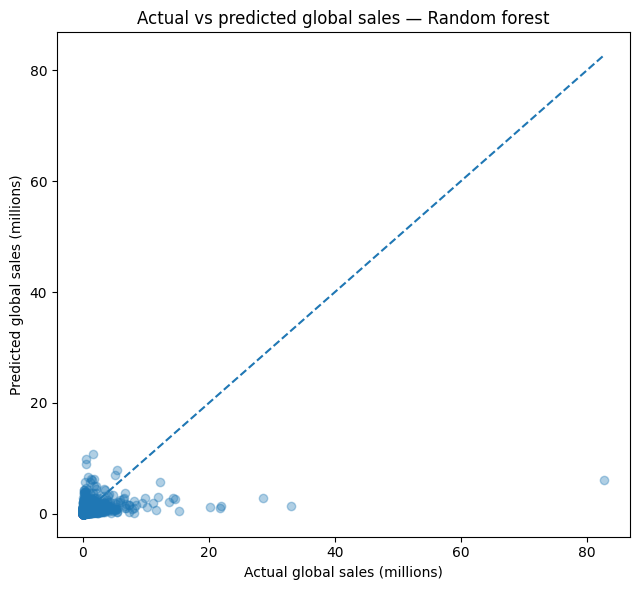

Best model by holdout RMSE: Random forest
Check the plotted spread and the metrics together; high-selling outliers can dominate RMSE.


In [50]:
# Inspect the best model's predictions and errors on the untouched holdout set.
best_model_name = model_results.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, best_predictions, alpha=0.35)
limit = max(float(y_test.max()), float(np.max(best_predictions)))
ax.plot([0, limit], [0, limit], linestyle="--")
ax.set_title(f"Actual vs predicted global sales — {best_model_name}")
ax.set_xlabel("Actual global sales (millions)")
ax.set_ylabel("Predicted global sales (millions)")
plt.tight_layout()
plt.show()

print(f"Best model by holdout RMSE: {best_model_name}")
print("Check the plotted spread and the metrics together; high-selling outliers can dominate RMSE.")

## Interpretation and limitations

- The median baseline provides a minimum benchmark; a more complex model should be judged by whether it improves on that baseline on unseen data.
- Platform, genre, publisher, and year are metadata proxies. The dataset does not contain marketing spend, price, review scores, distribution, or other factors that can influence sales.
- A random train/test split can place similar releases or titles from the same franchises in both partitions. A future extension could use a time-based split to test generalisation to later release years.
- Global sales are heavily right-skewed, so a small number of blockbuster titles may have a large effect on RMSE. MAE is useful as a complementary measure.
- Run the notebook from the top after opening it in Colab or a local Jupyter environment. The updated modelling cells have not been executed in this repository update, so fresh metric values will appear when you run them.

## Conclusion

This project explored historical video game sales data to identify patterns across genres, platforms, publishers, release years, and regional markets. Visualisations helped compare global and regional sales, examine release patterns, and identify the best-selling titles within the dataset.

The analysis highlighted the value of examining regional markets separately, as sales patterns can differ between North America, Europe, Japan, and other markets. It also demonstrated the importance of distinguishing total sales from average sales and release counts when interpreting commercial performance.

Machine learning models were developed to explore whether information such as platform, genre, publisher, and release year could help predict global sales. The models were evaluated against a baseline using cross-validation and holdout metrics. Their predictive performance was limited, showing that these features alone do not fully explain differences in game sales.

Overall, this project strengthened my practical experience in data cleaning, exploratory data analysis, visualisation, feature preprocessing, and regression model evaluation using Python.

**Key learning:** Reliable analysis requires careful data preparation, appropriate evaluation methods, honest interpretation of results, and a clear distinction between observed patterns and predictive performance.